# **1_preprocessing_crowd**

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving crowd_raw.csv to crowd_raw.csv


In [ ]:

df = pd.read_csv("crowd_raw.csv")

print("Ukuran dataset:", df.shape)

display(df.head())


Ukuran dataset: (1512, 4)


,nama_wisata,hari,jam,popularity_score
0,Candi Prambanan,0,6,10
1,Candi Prambanan,0,7,20
2,Candi Prambanan,0,8,30
3,Candi Prambanan,0,9,40
4,Candi Prambanan,0,10,50


In [ ]:

print("Informasi Dataset:")
df.info()

print("\nStatistik Dataset:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Duplikat:")
print(df.duplicated().sum())


Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1512 entries, 0 to 1511
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   nama_wisata       1512 non-null   object
 1   hari              1512 non-null   int64 
 2   jam               1512 non-null   int64 
 3   popularity_score  1512 non-null   int64 
dtypes: int64(3), object(1)
memory usage: 47.4+ KB

Statistik Dataset:


,hari,jam,popularity_score
count,1512.000000,1512.000000,1512.000000
mean,3.000000,11.500000,16.686508
std,2.000662,6.924477,26.485632
min,0.000000,0.000000,0.000000
25%,1.000000,5.750000,0.000000
50%,3.000000,11.500000,0.000000
75%,5.000000,17.250000,25.000000
max,6.000000,23.000000,100.000000



Missing Values:
nama_wisata         0
hari                0
jam                 0
popularity_score    0
dtype: int64

Data Duplikat:
0


In [ ]:
# Membuat salinan dataset
df_clean = df.copy()

# Memastikan tipe data sesuai
df_clean["nama_wisata"] = df_clean["nama_wisata"].astype(str)
df_clean["hari"] = df_clean["hari"].astype(int)
df_clean["jam"] = df_clean["jam"].astype(int)
df_clean["popularity_score"] = df_clean["popularity_score"].astype(int)

# Memastikan rentang nilai valid
df_clean = df_clean[
    (df_clean["hari"].between(0, 6)) &
    (df_clean["jam"].between(0, 23)) &
    (df_clean["popularity_score"].between(0, 100))
]

print("Jumlah data setelah cleaning:", len(df_clean))
display(df_clean.head())

Jumlah data setelah cleaning: 1512


,nama_wisata,hari,jam,popularity_score
0,Candi Prambanan,0,6,10
1,Candi Prambanan,0,7,20
2,Candi Prambanan,0,8,30
3,Candi Prambanan,0,9,40
4,Candi Prambanan,0,10,50


In [ ]:
# 0 = hari kerja
# 1 = akhir pekan

df_clean["is_weekend"] = df_clean["hari"].isin([5, 6]).astype(int)

display(df_clean.head())

,nama_wisata,hari,jam,popularity_score,is_weekend
0,Candi Prambanan,0,6,10,0
1,Candi Prambanan,0,7,20,0
2,Candi Prambanan,0,8,30,0
3,Candi Prambanan,0,9,40,0
4,Candi Prambanan,0,10,50,0


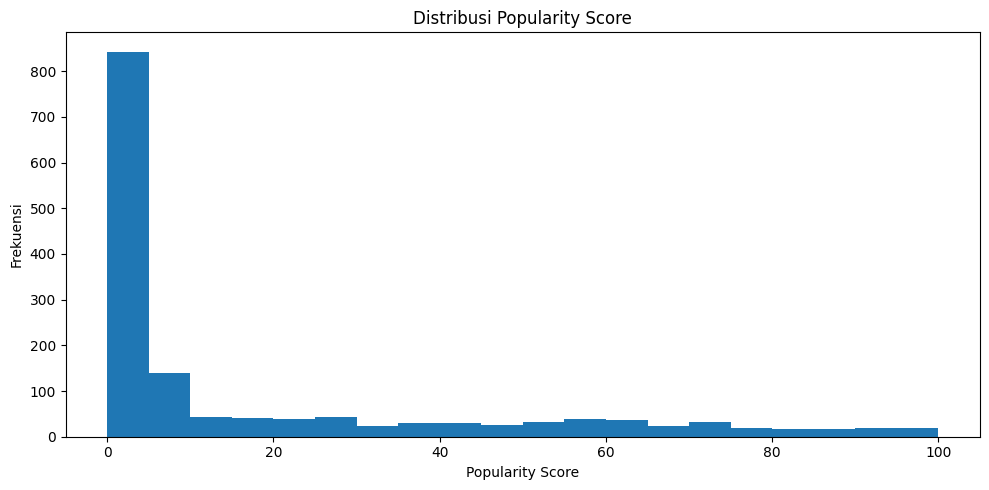

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(df_clean["popularity_score"], bins=20)

plt.title("Distribusi Popularity Score")
plt.xlabel("Popularity Score")
plt.ylabel("Frekuensi")

plt.tight_layout()
plt.show()

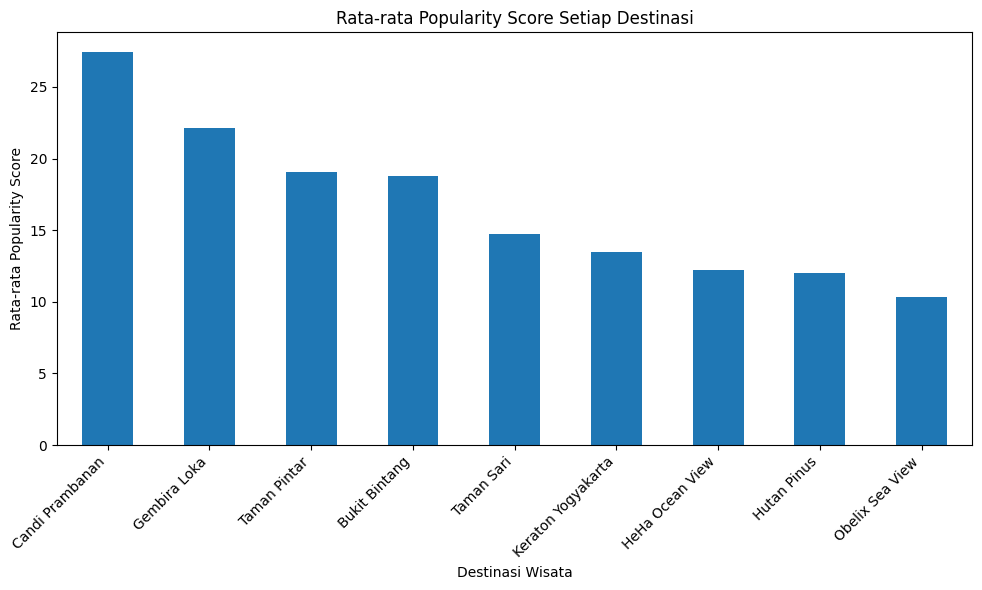

In [ ]:
rata_wisata = (
    df_clean.groupby("nama_wisata")["popularity_score"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

rata_wisata.plot(kind="bar")

plt.title("Rata-rata Popularity Score Setiap Destinasi")
plt.xlabel("Destinasi Wisata")
plt.ylabel("Rata-rata Popularity Score")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [ ]:
df_clean.to_csv("crowd_clean.csv", index=False)

print("Dataset berhasil disimpan!")
print("Ukuran dataset:", df_clean.shape)

Dataset berhasil disimpan!
Ukuran dataset: (1512, 5)


In [ ]:
from google.colab import files

files.download("crowd_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **2_training_crowd**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import joblib

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import warnings
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving crowd_clean.csv to crowd_clean (1).csv


In [ ]:
df = pd.read_csv("crowd_clean.csv")

print("Ukuran dataset:", df.shape)

display(df.head())

Ukuran dataset: (1512, 5)


,nama_wisata,hari,jam,popularity_score,is_weekend
0,Candi Prambanan,0,6,10,0
1,Candi Prambanan,0,7,20,0
2,Candi Prambanan,0,8,30,0
3,Candi Prambanan,0,9,40,0
4,Candi Prambanan,0,10,50,0


In [ ]:
# Fitur yang digunakan
X = df[
    [
        "nama_wisata",
        "hari",
        "jam",
        "is_weekend"
    ]
]

# Target prediksi
y = df["popularity_score"]

print("Jumlah fitur:", X.shape[1])
print("Jumlah target:", y.shape[0])

display(X.head())

Jumlah fitur: 4
Jumlah target: 1512


,nama_wisata,hari,jam,is_weekend
0,Candi Prambanan,0,6,0
1,Candi Prambanan,0,7,0
2,Candi Prambanan,0,8,0
3,Candi Prambanan,0,9,0
4,Candi Prambanan,0,10,0


In [ ]:
# Menggabungkan nama destinasi dan hari
# agar 24 jam dalam satu hari tidak terpisah
groups = df["nama_wisata"] + "_" + df["hari"].astype(str)

# Membagi data berdasarkan kelompok
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Data Training:", X_train.shape)
print("Data Testing:", X_test.shape)

print("Jumlah kelompok training:", groups.iloc[train_idx].nunique())
print("Jumlah kelompok testing:", groups.iloc[test_idx].nunique())

Data Training: (1200, 4)
Data Testing: (312, 4)
Jumlah kelompok training: 50
Jumlah kelompok testing: 13


In [ ]:
# Mengubah nama destinasi menjadi angka
preprocessor = ColumnTransformer(
    transformers=[
        (
            "destinasi",
            OneHotEncoder(handle_unknown="ignore"),
            ["nama_wisata"]
        )
    ],
    remainder="passthrough"
)

# Membuat model Random Forest
random_forest = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    min_samples_split=2,
    min_samples_leaf=2,
    n_jobs=-1
)

# Menggabungkan preprocessing dan model
model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("regressor", random_forest)
    ]
)

print("Model Random Forest berhasil dibuat!")

Model Random Forest berhasil dibuat!


In [ ]:
model.fit(X_train, y_train)

print("Training model berhasil!")

Training model berhasil!


In [ ]:
y_pred = model.predict(X_test)

hasil_prediksi = pd.DataFrame({
    "Aktual": y_test.values,
    "Prediksi": y_pred
})

display(hasil_prediksi.head(10))

,Aktual,Prediksi
0,0,0.000000
1,0,0.000000
2,0,0.000000
3,0,0.000000
4,0,0.000000
5,0,0.000000
6,15,11.137507
7,30,23.285701
8,45,39.503571
9,65,52.940556


In [ ]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("HASIL EVALUASI RANDOM FOREST")
print("============================")
print("MAE  :", round(mae, 2))
print("RMSE :", round(rmse, 2))
print("R2   :", round(r2, 4))

HASIL EVALUASI RANDOM FOREST
MAE  : 4.56
RMSE : 9.94
R2   : 0.8962


In [ ]:
baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)

print("BASELINE MODEL")
print("MAE :", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))

print("\nRANDOM FOREST")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))

BASELINE MODEL
MAE : 24.01
RMSE: 31.07

RANDOM FOREST
MAE : 4.56
RMSE: 9.94


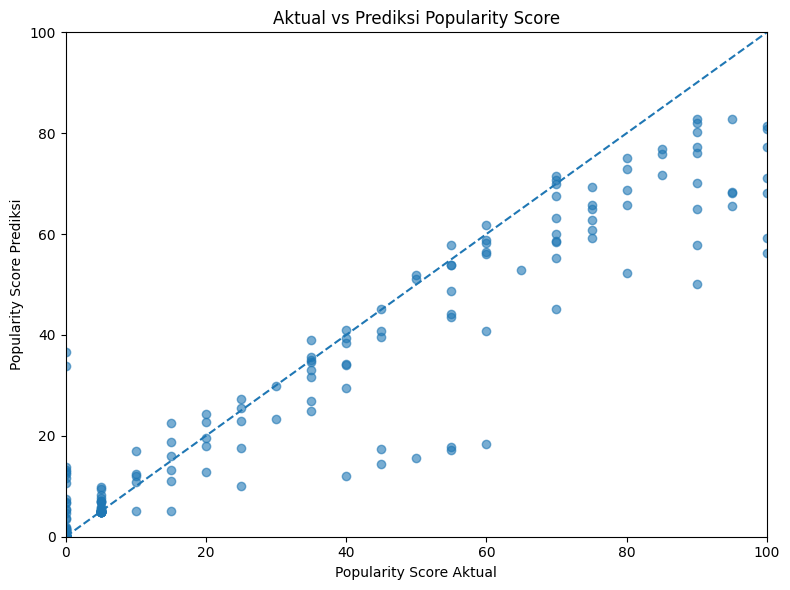

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--"
)

plt.title("Aktual vs Prediksi Popularity Score")
plt.xlabel("Popularity Score Aktual")
plt.ylabel("Popularity Score Prediksi")

plt.xlim(0, 100)
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [ ]:
# Mengambil nama fitur hasil preprocessing
feature_names = model.named_steps[
    "preprocessing"
].get_feature_names_out()

# Mengambil nilai feature importance
importance = model.named_steps[
    "regressor"
].feature_importances_

# Membuat tabel
feature_importance = pd.DataFrame({
    "Fitur": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Fitur,Importance
10,remainder__jam,0.540418
0,destinasi__nama_wisata_Bukit Bintang,0.084262
9,remainder__hari,0.073119
1,destinasi__nama_wisata_Candi Prambanan,0.055591
6,destinasi__nama_wisata_Obelix Sea View,0.052837
2,destinasi__nama_wisata_Gembira Loka,0.047228
3,destinasi__nama_wisata_HeHa Ocean View,0.036542
7,destinasi__nama_wisata_Taman Pintar,0.029635
11,remainder__is_weekend,0.028308
4,destinasi__nama_wisata_Hutan Pinus,0.022960


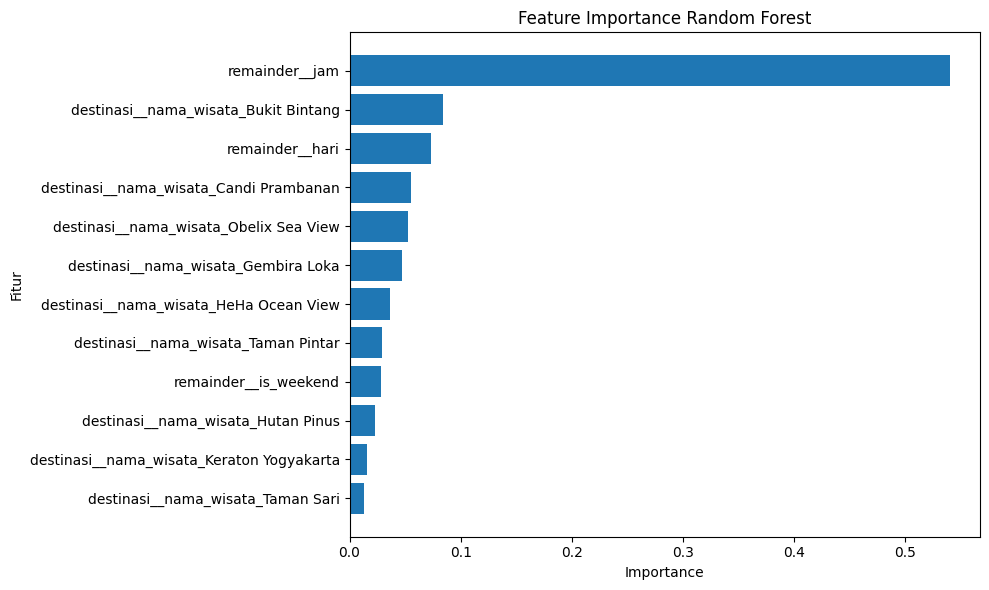

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Fitur"],
    feature_importance["Importance"]
)

plt.title("Feature Importance Random Forest")
plt.xlabel("Importance")
plt.ylabel("Fitur")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
joblib.dump(model, "model_crowd.pkl")

print("Model berhasil disimpan!")

Model berhasil disimpan!


In [ ]:
from google.colab import files

files.download("model_crowd.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sklearn

print("Versi Scikit-learn:", sklearn.__version__)

Versi Scikit-learn: 1.6.1
